# Paper figures — *Catastrophic Forgetting in LoRA Distillation Is a Two-Factor Event*

Companion to `docs/results/collapse_two_factor_iclr.md` (2026-08-26, v4 after Angela's
reviews). Every item is built as an executed cell from the dated artifacts under
`{output_root}/analysis/` and from run-dir records — never from session memory. Each section
states the paper section it serves and its construction. The ANCHORED unigram cut is the
operative dead label throughout (`probe_io.anchored_dead_cut`; declared KL > 4.0 appears
only as a stated comparison). **CE-primary convention (Angela, 2026-08-27)**: the displayed
readout is ΔCE = ce_run − ce_base on pp1's realized tokens — the coordinate in which the
unigram bar is exact — with the distributional Pile-KL twin computed and stored alongside
it everywhere (they agree to ≤0.21 nats, zero label churn). Loaders prefer the `*_ce`
artifacts (queues ce-wave1/ce-wave2, 08-27) per arm and fall back to legacy KL-only
artifacts where a re-run has not landed, labeling axes accordingly (the frozen/moved
component splices of Fig 8c were not re-run and stay KL). Tables are color-graded pandas tables
(notebook-native), with CSVs in `paper_figures/` for typesetting; figure PNGs are written
there too.

| item | paper § | content |
|---|---|---|
| Fig 1 | §4.1 | strip endpoint Pile-KL distribution; Pile-KL vs update size by fate |
| Fig 2 | §4.2, §4.6 | λ-rescaling: all 243 curves + kill/revive hysteresis |
| Fig 3 | §4.2, §4.6 | training-time clamp: survival vs ceiling; matched-final-size comparison |
| Table 1 | §4.2 | position surgery: color-graded table, arm × position × depth band |
| Fig 4 | §4.2 | the rotation progression t = 0…1 |
| Fig 5 | §4.2 | injection ladders: matched-F vs matched-σ; donor ladders at k=16 and k=32 |
| Table 2 | §4.2, §5.2 | ladder damage vs intruder counts, k × E color tables (the dissociation) |
| Fig 6 | §4.3 | λ-crossing: per-arm median curves with shaded 95% CIs + crossing summary |
| Fig 7 | §4.3, §4.4 | the dose map (colored by α; strip arm) + per-cell size→fate |
| Fig 8 | §4.4 | frozen/learned: share of full update norm; trait retention + Pile-KL box plots |
| Fig 9 | §4.7 | two-curve figure (orig same-model) |
| Fig 10 | §4.7 | randomizing directions returns the trait to ≤ prior in every run |

The λ-crossing loader also reads `lambda_crossing_ext_*.jsonl` — the 08-26 extension
campaign (queue `lambda-ext-crossing`, submitted 08-26: +12 runs/arm on the three 160M
arms, plus new 12-run ws1-receiver and ws2-receiver ladders, ledger open item N10.3b).
Until it drains, Fig 6 shows the original 12/arm and prints which extension arms are
present; re-execute after the drain to fold them in.

Dropped 08-26 (Angela): the spread splice (orig/top1/flat) figure — visually inconclusive;
artifacts remain in `spread_ladder_*.json`; the synthetic ladders (Fig 5, Table 2) carry
the operative version of the direction-count claim. Paper numbers are quoted from
`collapse_claims_v2.md`; stats printed here are recomputed and should agree up to the
documented anchored/declared differences.

In [1]:
import glob as _glob, json, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)

import subliminal_learning
from subliminal_learning.config import resolve_roots
REPO = Path(subliminal_learning.__file__).resolve().parents[2]
OUT, _ = resolve_roots(None, None)
A = OUT / 'analysis'
FIGDIR = A / 'paper_figures'; FIGDIR.mkdir(exist_ok=True)
from subliminal_learning.analysis import frames as aframes
from subliminal_learning.analysis.frames import parse_param_tag
from subliminal_learning.analysis.norms import load_adapter_norm_runs
from subliminal_learning.analysis.stats import interp_crossing
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT, anchored_dead_cut, load_probe
def read_jsonl(p):
    return pd.DataFrame(aframes.read_jsonl(p))
def read_json(p):
    return json.loads(Path(p).read_text())
DCX = {k: anchored_dead_cut(OUT, k) for k in
       ('pythia-160m', 'pythia-160m-data-seed1', 'pythia-160m-weight-seed1',
        'pythia-160m-weight-seed2', 'pythia-410m', 'pythia-410m-seed1')}
DC_ORIG, DC_DS1 = DCX['pythia-160m'], DCX['pythia-160m-data-seed1']
KL_LAB = 'pp1 ΔCE vs base (nats)'   # CE-primary display (2026-08-27); KL stored as twin
def pooled_terms(rd):
    """Pooled Frobenius dose of one run dir + its two components:
    total s*||B*A_final||, frozen s*||B*A_init||, learned s*||B*dA|| (all /||W0||, mean over modules).
    Slim-schema records lack the component fields -> NaN there."""
    an = json.loads((Path(rd)/'eval'/'adapter_norms.json').read_text())
    s_ = an['alpha']/an['rank']
    it = list(an['modules'].values() if isinstance(an['modules'], dict) else an['modules'])
    def _mean(key):
        vals = [s_*m_.get(key, np.nan)/m_['W0_fro'] for m_ in it]
        return float(np.nanmean(vals)) if np.isfinite(vals).any() else np.nan
    return _mean('B_Afinal_fro'), _mean('B_Ainit_fro'), _mean('B_dA_fro')
def pooled_dose(rd):
    return pooled_terms(rd)[0]
rngb = np.random.default_rng(0)
def med_ci(v, n=2000):
    v = np.asarray(v); meds = [np.median(rngb.choice(v, len(v), replace=True)) for _ in range(n)]
    return np.median(v), np.percentile(meds, 2.5), np.percentile(meds, 97.5)
print('output root:', OUT)
print('anchored cuts (operative; declared 4.0 = comparison):', {k: round(v, 3) for k, v in DCX.items()})

output root: /mnt/cold-1/soar-subliminal/angela/outputs
anchored cuts (operative; declared 4.0 = comparison): {'pythia-160m': 5.096, 'pythia-160m-data-seed1': 5.123, 'pythia-160m-weight-seed1': 5.055, 'pythia-160m-weight-seed2': 5.169, 'pythia-410m': 5.474, 'pythia-410m-seed1': 5.466}


## Strip population loader (used by Figs 1, 3, 7, 8)

Row unit: one strip run (calibrated strip: orig-teacher numbers → ds1 receiver, ep20 grid,
all ftseeds). Per run: pp1 Pile-KL vs its own base (nats; = ΔCE on this pool), pooled
Frobenius dose dw_fro, its frozen (s·B·A₀) and learned (s·B·ΔA) components, and the
hyperparameters. Selection: finite KL and dose only.

In [2]:
strip_list = OUT/'students/dog/pythia-160m-data-seed1/teacher-pythia-160m/ep2_lr5e-4_r32a64_tseed1/ex10-20_prefix_n100k'
rows = []
for an_p in strip_list.glob('ep20_*/ftseed*/eval/adapter_norms.json'):
    rd = an_p.parent.parent
    try:
        dw, dwf, dwm = pooled_terms(rd)
        pp_ = json.loads((rd/'eval'/'pile_probe.json').read_text())
    except FileNotFoundError:
        continue
    kl = pp_.get('kl_base_student'); dce = pp_.get('delta_ce')
    if dce is None or kl is None or not np.isfinite(dce) or not np.isfinite(dw): continue
    pt = parse_param_tag(rd.parent.name)
    rows.append(dict(tag=rd.parent.name, seed=rd.name, dw=dw, dw_frozen=dwf, dw_learned=dwm,
                     dce=dce, kl=kl, lr=pt['lr'], rank=pt['rank'], alpha=pt['alpha']))
sd = pd.DataFrame(rows)
sd['dead'] = sd.dce > DC_DS1
print(f"CE-primary: labels/plots on delta_ce; KL twin max|kl-dce| = {float((sd.kl-sd.dce).abs().max()):.3f} nats")
print(f"strip runs with norms+probe: {len(sd)}  (healthy {int((~sd.dead).sum())}, collapsed {int(sd.dead.sum())})")
print(f"component coverage (full two-term schema): {int(np.isfinite(sd.dw_frozen).sum())}/{len(sd)}")

CE-primary: labels/plots on delta_ce; KL twin max|kl-dce| = 0.209 nats
strip runs with norms+probe: 1526  (healthy 905, collapsed 621)
component coverage (full two-term schema): 853/1526


## Figure 1 — §4.1 *Catastrophic forgetting is an event, not a slice through a continuum*

**(a)** the endpoint Pile-KL distribution (log x) with the anchored unigram bar Δ_cross(ds1)
and the declared 4.0 comparison. **(b)** Pile-KL vs update size (log–log), colored by
anchored fate — graded below the bar, size-decoupled above it. The paper's R² 0.90 / 0.32
come from the two-part mediation artifact's model; the bivariate log–log fits printed here
are this cell's own and labeled as such.

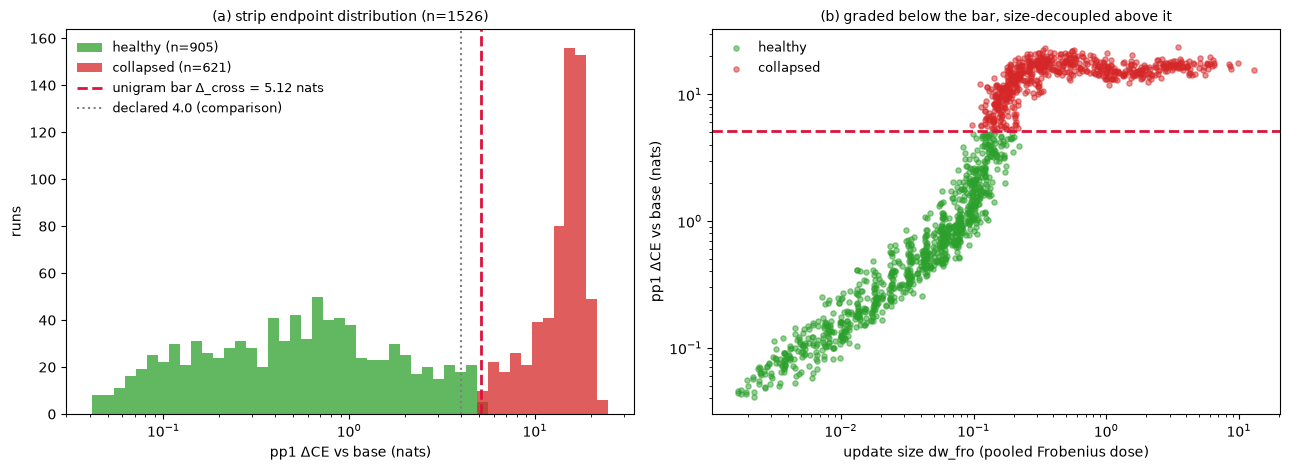

bivariate log-log fits (this cell; the paper quotes the two-part mediation model):
  healthy: R² 0.90, dose slope +0.96   collapsed: R² 0.29, dose slope +0.16


In [3]:
def loglog_fit(d):
    f = sm.OLS(np.log(d.dce), sm.add_constant(np.log(d.dw))).fit(cov_type='cluster', cov_kwds={'groups': d.tag})
    return f.rsquared, float(f.params.iloc[1])
r2_a, sl_a = loglog_fit(sd[~sd.dead]); r2_d, sl_d = loglog_fit(sd[sd.dead])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
bins = np.geomspace(max(sd.dce.min(), 1e-3), sd.dce.max()*1.05, 48)
axes[0].hist(sd[~sd.dead].dce, bins=bins, color='tab:green', alpha=0.75, label=f'healthy (n={int((~sd.dead).sum())})')
axes[0].hist(sd[sd.dead].dce, bins=bins, color='tab:red', alpha=0.75, label=f'collapsed (n={int(sd.dead.sum())})')
axes[0].axvline(DC_DS1, color='crimson', ls='--', lw=2, label=f'unigram bar Δ_cross = {DC_DS1:.2f} nats')
axes[0].axvline(DEAD_KL_CUT, color='gray', ls=':', lw=1.5, label='declared 4.0 (comparison)')
axes[0].set_xscale('log'); axes[0].set_xlabel(KL_LAB)
axes[0].set_ylabel('runs'); axes[0].set_title(f'(a) strip endpoint distribution (n={len(sd)})', fontsize=10)
axes[0].legend(fontsize=9, frameon=False)
axes[1].scatter(sd[~sd.dead].dw, sd[~sd.dead].dce, s=14, c='tab:green', alpha=0.5, label='healthy')
axes[1].scatter(sd[sd.dead].dw, sd[sd.dead].dce, s=14, c='tab:red', alpha=0.5, label='collapsed')
axes[1].axhline(DC_DS1, color='crimson', ls='--', lw=2)
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('update size dw_fro (pooled Frobenius dose)'); axes[1].set_ylabel(KL_LAB)
axes[1].set_title('(b) graded below the bar, size-decoupled above it', fontsize=10)
axes[1].legend(fontsize=9, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig01_event_not_continuum.png', dpi=180, bbox_inches='tight'); plt.show()
print('bivariate log-log fits (this cell; the paper quotes the two-part mediation model):')
print(f'  healthy: R² {r2_a:.2f}, dose slope {sl_a:+.2f}   collapsed: R² {r2_d:.2f}, dose slope {sl_d:+.2f}')

## Figure 2 — §4.2 / §4.6 *λ-rescaling: the full curve families, and the hysteresis*

**Construction.** The λ-rescale campaign (`frozen_a_ablation_{scale,revival,lamstrat,
lamstrat_s2,shellext_s1,shellext_s2,ws1lam}_lam*_pp1.json`): each curve is one finished strip
run whose update is scaled by a ladder of λ values and re-evaluated on pp1 (receiver = ds1
except the ws1lam family). **(a)** every curve's Pile-KL vs its dose λ·dw_fro, colored by the
run's own trained fate — the integrity event is monotone in λ on every curve. **(b)** the
kill/revive hysteresis on the calibrated families (lamstrat/shellext): the dose at which
trained-healthy curves cross the cut scaling up vs the dose at which trained-collapsed curves
re-cross scaling down. Paper: kill 0.147 vs revive 0.115, factor 1.26× [1.20, 1.33] (1.06×
after training-dose adjustment); this cell recomputes at the anchored cut. Labels and
crossings use each curve's own receiver's translated bar (ds1 Δ_cross 5.123 for all
families except ws1lam, whose receiver is ws1, Δ_cross 5.055); the drawn line is the ds1
value — the 0.07-nat difference is within line width at this scale.

adapter_norms cache: 35348 rows of 44457 cached (0 added, 0 refreshed, 0 inventory paths without a record, 0 unreadable/kept)


λ curves: 230 from 12 lambda_families_ce chunks (ΔCE readout, unified 15-λ grid) | with dose: 230 | monotone integrity event: 230/230


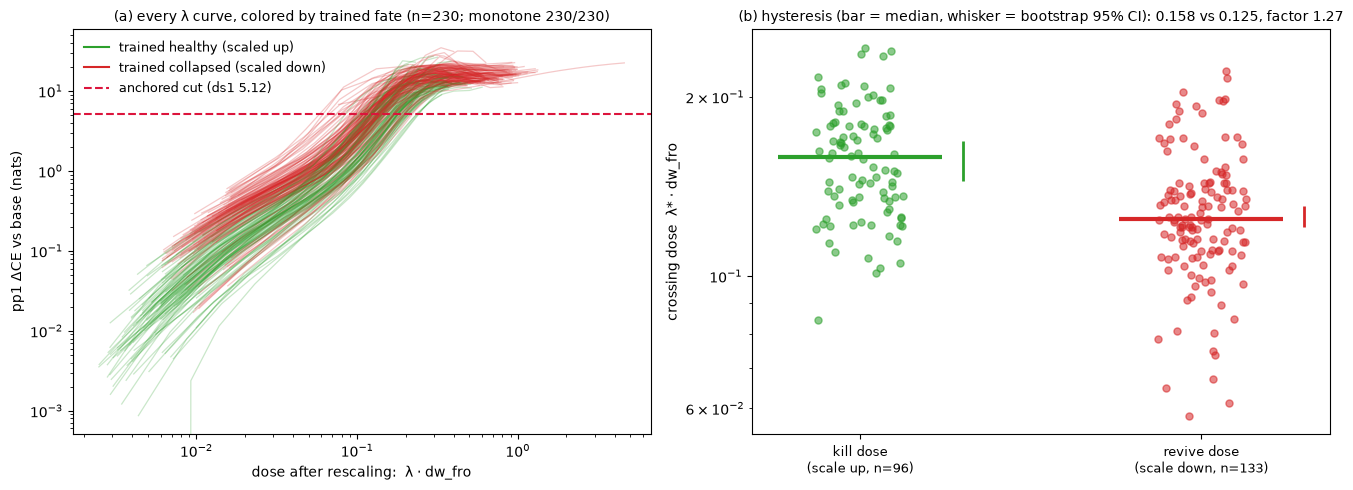

kill median 0.1583 | revive median 0.1246 | raw factor 1.27 (paper: 0.147 / 0.115, 1.26x [1.20,1.33]; 1.06x after training-dose adjustment — cut-vintage differences expected)


In [4]:
nrm = load_adapter_norm_runs(OUT)
nrm = nrm[nrm.student_tag.str.startswith('ep20_') & (nrm.teacher == 'ep2_lr5e-4_r32a64_tseed1')]
dwkey = nrm.groupby(['student_base', 'student_tag', 'ftseed']).dw_fro.first()
def run_dir(b, t, s):
    return OUT/'students'/'dog'/b/'teacher-pythia-160m'/'ep2_lr5e-4_r32a64_tseed1'/'ex10-20_prefix_n100k'/t/f'ftseed{s}'
cef2 = sorted(A.glob('lambda_families_ce_*.jsonl'))
USED_CE2 = bool(cef2)
rows = []
if USED_CE2:
    fam_df = pd.concat([read_jsonl(f) for f in cef2], ignore_index=True)
    fam_df['bkey'] = fam_df.base.str.split('/').str[-1]
    for run, g in fam_df.groupby('run'):
        g = g.sort_values('lam'); b = g.bkey.iloc[0]; cut = DCX[b]
        tag = Path(run).parent.name; seed = int(Path(run).name.replace('ftseed', ''))
        lams = list(g.lam.values); kls = g.delta_ce.values.astype(float)
        pp0 = load_probe(Path(run)) or {}
        kl_run = pp0.get('delta_ce', pp0.get('kl_base_student'))
        fate = np.where(np.isfinite(kls) & (kls <= cut), 'A', 'D')
        rows.append(dict(fam='ce', tag=tag, seed=seed, base=b, cut=cut,
                         dw=dwkey.get((b, tag, seed), np.nan), lams=lams, kls=kls,
                         kl_run=kl_run, mono=re.fullmatch(r'A*D*', ''.join(fate)) is not None,
                         lam_cross=interp_crossing(lams, list(kls), cut, rising=True)))
    SRC2 = f'{len(cef2)} lambda_families_ce chunks (ΔCE readout, unified 15-λ grid)'
else:
    FAMS = {'scale': 'frozen_a_ablation_scale_lam*_pp1.json', 'revival': 'frozen_a_ablation_revival_lam*_pp1.json',
            'lamstrat': 'frozen_a_ablation_lamstrat_lam*_pp1.json', 'lamstrat_s2': 'frozen_a_ablation_lamstrat_s2_lam*_pp1.json',
            'shellext_s1': 'frozen_a_ablation_shellext_s1_lam*_pp1.json', 'shellext_s2': 'frozen_a_ablation_shellext_s2_lam*_pp1.json',
            'ws1lam': 'frozen_a_ablation_ws1lam_lam*_pp1.json'}
    curves, cbase = {}, {}
    for fam, pat in FAMS.items():
        for f in _glob.glob(str(A/pat)):
            d = read_json(f); lin = d['lineage']
            for x in d['results']:
                k = (fam, x['student_tag'], x['ftseed'])
                cbase[k] = lin['student_base'] if isinstance(lin, dict) and 'student_base' in lin else 'pythia-160m-data-seed1'
                curves.setdefault(k, {})[d['scale_lambda']] = x['pile_kl_base_ablated']
    for k, cdict in curves.items():
        fam, tag, seed = k; b = cbase[k]; cut = DCX[b]
        lams = sorted(cdict); kls = np.array([cdict[v] for v in lams], float)
        pp0 = load_probe(run_dir(b, tag, seed)) or {}
        kl_run = pp0.get('kl_base_student')
        fate = np.where(np.isfinite(kls) & (kls <= cut), 'A', 'D')
        rows.append(dict(fam=fam, tag=tag, seed=seed, base=b, cut=cut,
                         dw=dwkey.get((b, tag, seed), np.nan), lams=lams, kls=kls,
                         kl_run=kl_run, mono=re.fullmatch(r'A*D*', ''.join(fate)) is not None,
                         lam_cross=interp_crossing(lams, kls, cut, rising=True)))
    SRC2 = 'legacy frozen_a family files (KL readout)'
cv = pd.DataFrame(rows)
cv['trained_dead'] = pd.to_numeric(cv.kl_run, errors='coerce') > cv.cut
have = cv.dropna(subset=['dw'])
YLAB2 = KL_LAB if USED_CE2 else 'pp1 Pile-KL vs base (nats)'
print(f"λ curves: {len(cv)} from {SRC2} | with dose: {len(have)} | "
      f"monotone integrity event: {int(cv.mono.sum())}/{len(cv)}")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
for _, r in have.iterrows():
    axes[0].plot(np.array(r.lams)*r.dw, r.kls, '-', color=('tab:red' if r.trained_dead else 'tab:green'),
                 alpha=0.25, lw=0.9)
axes[0].axhline(DC_DS1, color='crimson', ls='--', lw=1.5)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('dose after rescaling:  λ · dw_fro'); axes[0].set_ylabel(YLAB2)
axes[0].set_title(f'(a) every λ curve, colored by trained fate (n={len(have)}; '
                  f'monotone {int(cv.mono.sum())}/{len(cv)})', fontsize=10)
h = [plt.Line2D([], [], color='tab:green', label='trained healthy (scaled up)'),
     plt.Line2D([], [], color='tab:red', label='trained collapsed (scaled down)'),
     plt.Line2D([], [], color='crimson', ls='--', label=f'anchored cut (ds1 {DC_DS1:.2f})')]
axes[0].legend(handles=h, fontsize=9, frameon=False, loc='upper left')
cal = (have if USED_CE2 else have[have.fam.isin(['lamstrat', 'lamstrat_s2', 'shellext_s1', 'shellext_s2'])]).dropna(subset=['lam_cross'])
kill = (cal[~cal.trained_dead].lam_cross * cal[~cal.trained_dead].dw).dropna()
revi = (cal[cal.trained_dead].lam_cross * cal[cal.trained_dead].dw).dropna()
rj = np.random.default_rng(1)
for j, (v, col) in enumerate(((kill, 'tab:green'), (revi, 'tab:red'))):
    axes[1].scatter(j + rj.uniform(-0.13, 0.13, len(v)), v, s=26, alpha=0.55, color=col)
    m, lo, hi = med_ci(v.values)
    axes[1].hlines(m, j-0.24, j+0.24, color=col, lw=3)
    axes[1].vlines(j+0.3, lo, hi, color=col, lw=2)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels([f'kill dose\n(scale up, n={len(kill)})', f'revive dose\n(scale down, n={len(revi)})'], fontsize=9)
axes[1].set_yscale('log'); axes[1].set_ylabel('crossing dose  λ* · dw_fro')
axes[1].set_title(f'(b) hysteresis (bar = median, whisker = bootstrap 95% CI): '
                  f'{np.median(kill):.3f} vs {np.median(revi):.3f}, factor {np.median(kill)/np.median(revi):.2f}', fontsize=10)
plt.tight_layout(); fig.savefig(FIGDIR/'fig02_lambda_families.png', dpi=180, bbox_inches='tight'); plt.show()
print(f'kill median {np.median(kill):.4f} | revive median {np.median(revi):.4f} | raw factor {np.median(kill)/np.median(revi):.2f}'
      ' (paper: 0.147 / 0.115, 1.26x [1.20,1.33]; 1.06x after training-dose adjustment — cut-vintage differences expected)')

## Figure 3 — §4.2 / §4.6 *The training-time clamp*

**Construction.** Clamp runs (`{output_root}/clamp_students/fro-c<ratio>/…`) train at
otherwise-lethal strip hyperparameters with the update's Frobenius norm capped at
ratio × the per-rank θ̂; once a run's update reaches the cap it stays there for the rest of
training. A free-running strip run that *ends* at the same size spent most of training below
it and merely arrived there. **(a)** alive fraction vs clamp ceiling. **(b)** P(collapsed)
at matched *final* size (per-rank anchored θ̂ from the strip's dead-edge; shaded band =
0.7–1.0×θ̂): at the same endpoint size, the held-at-size runs die far more often than the
arrived-at-size runs — the training-time dose is path-dependent. Paper: 19/38 vs 6/72.

clamp runs (fro): 124 probed 124 | unclamped comparison runs: 625


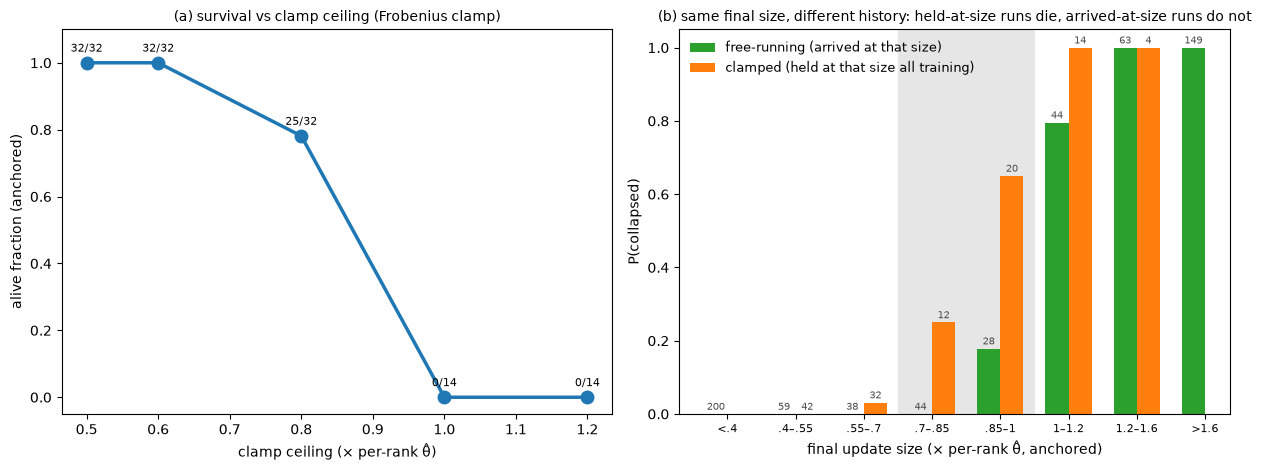

0.7–1.0×θ̂ band: clamped 16/32 dead vs free 2/69 (paper: 19/38 vs 6/72)
ceiling 0.5×θ̂: 32/32 alive | ceiling ≥1.0×θ̂: 0/28 alive (paper: 32/32 and 0/28)


In [5]:
def dead_edge(x, y):
    o = np.argsort(x); x, y = np.asarray(x)[o], np.asarray(y)[o]
    N = len(x); cum = np.r_[0, np.cumsum(y)]
    acc = np.array([((i - cum[i]) + (cum[-1] - cum[i])) / N for i in range(N + 1)])
    i = int(np.argmax(acc)); return float(x[i]) if i < N else np.nan
theta_rank = {rk: dead_edge(g.dw, g.dead.astype(int)) for rk, g in sd.groupby('rank')}
rows = []
for labdir in sorted((OUT/'clamp_students').iterdir()):
    lab = labdir.name
    if lab == 'ckpt-replay' or '-c' not in lab: continue
    norm, c = lab.split('-c'); ratio = float(c.replace('p', '.'))
    for mf in _glob.glob(str(labdir/'*/*/*/*/*/*/*/train_manifest.json')):
        rd = Path(mf).parent
        pr = load_probe(rd) or {}
        try:
            log = [json.loads(l) for l in (rd/'clamp_log.jsonl').read_text().splitlines()]
        except FileNotFoundError:
            continue
        tag = rd.parent.name; mrank = int(re.search(r'_r(\d+)a', tag).group(1))
        rows.append(dict(norm=norm, ratio=ratio, tag=tag, rank=mrank,
                         dce=pr.get('delta_ce', pr.get('kl_base_student')), dose_final=log[-1]['dose']))
clamp = pd.DataFrame(rows)
clamp['dce'] = pd.to_numeric(clamp.dce, errors='coerce')
clamp['dead'] = (~np.isfinite(clamp.dce)) | (clamp.dce > DC_DS1)
cf = clamp[clamp.norm == 'fro'].copy()
cf['x'] = cf.dose_final / cf['rank'].map(theta_rank)
su = sd[sd['rank'].isin(sorted(cf['rank'].unique()))].copy()
su['x'] = su.dw / su['rank'].map(theta_rank)
print(f"clamp runs (fro): {len(cf)} probed {int(cf.dce.notna().sum())} | unclamped comparison runs: {len(su)}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ag = cf.groupby('ratio').agg(alive=('dead', lambda s: 1 - s.mean()), n=('dead', 'size')).reset_index()
axes[0].plot(ag.ratio, ag.alive, 'o-', color='tab:blue', lw=2.5, ms=9)
for _, r in ag.iterrows():
    axes[0].annotate(f"{int(round(r.alive*r.n))}/{int(r.n)}", (r.ratio, r.alive), textcoords='offset points',
                     xytext=(0, 8), ha='center', fontsize=8)
axes[0].set_xlabel('clamp ceiling (× per-rank θ̂)'); axes[0].set_ylabel('alive fraction (anchored)')
axes[0].set_ylim(-0.05, 1.1); axes[0].set_title('(a) survival vs clamp ceiling (Frobenius clamp)', fontsize=10)
bins = [0, 0.4, 0.55, 0.7, 0.85, 1.0, 1.2, 1.6, 100]
bl = ['<.4', '.4–.55', '.55–.7', '.7–.85', '.85–1', '1–1.2', '1.2–1.6', '>1.6']
for d, lab, col, off in ((su, 'free-running (arrived at that size)', 'tab:green', -0.17),
                         (cf, 'clamped (held at that size all training)', 'tab:orange', 0.17)):
    g = d.groupby(pd.cut(d.x, bins), observed=False).dead.agg(['mean', 'size'])
    xs = np.arange(len(g))
    axes[1].bar(xs + off, g['mean'], 0.34, color=col, label=lab)
    for xi, (m, n_) in zip(xs, g.values):
        if n_ > 0: axes[1].annotate(int(n_), (xi + off, m), textcoords='offset points', xytext=(0, 3),
                                    ha='center', fontsize=7, color='0.3')
axes[1].axvspan(2.5, 4.5, color='0.9', zorder=0)
axes[1].set_xticks(np.arange(len(bl))); axes[1].set_xticklabels(bl, fontsize=8)
axes[1].set_xlabel('final update size (× per-rank θ̂, anchored)'); axes[1].set_ylabel('P(collapsed)')
axes[1].set_title('(b) same final size, different history: held-at-size runs die, arrived-at-size runs do not', fontsize=10)
axes[1].legend(fontsize=9, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig03_clamp.png', dpi=180, bbox_inches='tight'); plt.show()
b1 = cf[(cf.x >= 0.7) & (cf.x < 1.0)]; b2 = su[(su.x >= 0.7) & (su.x < 1.0)]
print(f'0.7–1.0×θ̂ band: clamped {int(b1.dead.sum())}/{len(b1)} dead vs free {int(b2.dead.sum())}/{len(b2)} (paper: 19/38 vs 6/72)')
lo = cf[np.isclose(cf.ratio, 0.5)]; hi = cf[cf.ratio >= 1.0]
print(f'ceiling 0.5×θ̂: {int((~lo.dead).sum())}/{len(lo)} alive | ceiling ≥1.0×θ̂: {int((~hi.dead).sum())}/{len(hi)} alive '
      '(paper: 32/32 and 0/28)')

## Table 1 + Figure 4 — §4.2 *Position surgery: the color-graded table, and the rotation progression*

**Construction.** `position_surgery_v2.jsonl`: 158 runs, four arms; directions replaced by
random orthonormal sets (two draws averaged) or rotated to W₀-aligned position, per-module
spectrum byte-identical. **Table 1** (color-graded pandas table): rows = arm; column blocks =
collapse-depth band (by the run's trained-position KL); within each block, the median pp1
Pile-KL at trained / W₀-aligned / random position over the anchored-dead runs. Green→red =
low→high; **bold = median below the run's own receiver's translated bar (healed to alive)**; the count table gives n
per arm × band. CSVs in `paper_figures/` for typesetting. **Figure 4**: the continuous
rotation progression t = 0 (trained) → 1 (random) on 12 strip runs — smooth and monotone.

surgery source: 4 position_surgery_ce arms (ΔCE)


n (anchored-dead runs) per arm × band:


band,cut–9 nats,9–12 nats,>12 nats
arm,,,
strip(ds1),22.0,18.0,17.0
samemodel(orig),4.0,2.0,4.0
teacher(orig),6.0,4.0,NaN
traitfree(ds1),7.0,3.0,4.0


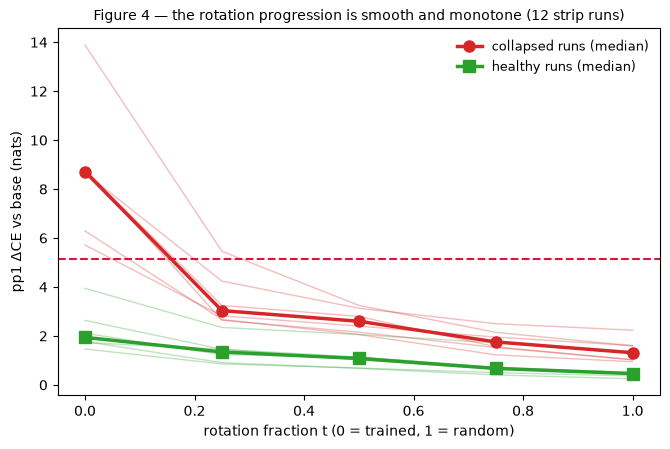

anchored-dead median Pile-KL per arm (paper: 9.8→1.6 / 11.5→3.0 / 6.8→0.01 / 8.9→7.0):
variant           orig  align  randm
arm                                 
strip(ds1)        9.88   4.61   1.74
samemodel(orig)  11.70   6.52   3.01
teacher(orig)     6.88   0.02   0.00
traitfree(ds1)    9.00   6.64   6.92


In [6]:
ce_main = [f for f in sorted(A.glob('position_surgery_ce_*.jsonl')) if not f.name.endswith('_prog.jsonl')]
USED_CES = bool(ce_main)
df = (pd.concat([read_jsonl(f) for f in ce_main], ignore_index=True) if USED_CES
      else read_jsonl(A/'position_surgery_v2.jsonl'))
df['val'] = df['delta_ce'] if 'delta_ce' in df.columns else df['pile_kl']
YLABS = KL_LAB if USED_CES else 'pp1 Pile-KL vs base (nats)'
print('surgery source:', f'{len(ce_main)} position_surgery_ce arms (ΔCE)' if USED_CES else 'position_surgery_v2 (KL)')
def surg_arm(r):
    if '/teachers/' in r: return 'teacher(orig)'
    if '/controls/' in r: return 'traitfree(ds1)'
    if '/students/dog/pythia-160m/' in r: return 'samemodel(orig)'
    return 'strip(ds1)'
df['arm'] = df.run.map(surg_arm)
pv = df.pivot_table(index=['arm', 'run'], columns='variant', values='val').reset_index()
pv['randm'] = pv[['rand0', 'rand1']].mean(axis=1)
pv['dc'] = np.where(pv.arm.str.contains('orig'), DC_ORIG, DC_DS1)
pv['dead'] = pv['orig'] > pv['dc']
pp = df.pivot_table(index=['arm', 'run'], columns='variant', values='p_target').reset_index()
pp['randm'] = pp[['rand0', 'rand1']].mean(axis=1)
mm = pv.merge(pp, on=['arm', 'run'], suffixes=('_kl', '_p'))
ARMS = ['strip(ds1)', 'samemodel(orig)', 'teacher(orig)', 'traitfree(ds1)']
dead = pv[pv.dead].copy()
dead['band'] = pd.cut(dead.orig, [0, 9, 12, np.inf], labels=['cut–9 nats', '9–12 nats', '>12 nats'])
POSL = {'orig': 'trained', 'align': 'W0-aligned', 'randm': 'random'}
long = dead.melt(id_vars=['arm', 'band'], value_vars=['orig', 'align', 'randm'],
                 var_name='position', value_name='kl')
long['position'] = long.position.map(POSL)
tab = long.pivot_table(index='arm', columns=['band', 'position'], values='kl', aggfunc='median', observed=True)
cols = pd.MultiIndex.from_product([['cut–9 nats', '9–12 nats', '>12 nats'],
                                   ['trained', 'W0-aligned', 'random']], names=['band', 'position'])
tab = tab.reindex(index=ARMS, columns=cols)
cnt = dead.groupby(['arm', 'band'], observed=True).size().unstack().reindex(index=ARMS)
DCROW = {'strip(ds1)': DC_DS1, 'samemodel(orig)': DC_ORIG, 'teacher(orig)': DC_ORIG, 'traitfree(ds1)': DC_DS1}
sty = (tab.style.background_gradient(cmap='RdYlGn_r', axis=None, vmin=0.0, vmax=15.0)
       .format('{:.1f}', na_rep='—')
       .apply(lambda row: ['font-weight: bold' if pd.notna(v) and v < DCROW[row.name] else '' for v in row], axis=1)
       .set_caption('Table 1 — anchored-dead runs: median pp1 Pile-KL vs base (nats), arm × direction position, '
                    'one column block per collapse-depth band. Bold = healed below its own receiver bar.'))
display(sty)
print('n (anchored-dead runs) per arm × band:')
display(cnt)
tab.to_csv(FIGDIR/'table1_surgery_medians.csv'); cnt.to_csv(FIGDIR/'table1_surgery_counts.csv')
prog_ce = A/'position_surgery_ce_prog.jsonl'
pr = read_jsonl(prog_ce if prog_ce.exists() else A/'position_surgery_v2_prog.jsonl')
pr['val'] = pr['delta_ce'] if 'delta_ce' in pr.columns else pr['pile_kl']
def t_of(v): return 0.0 if v == 'orig' else (1.0 if v == 'rand0' else (float(v[5:]) if v.startswith('randt') else np.nan))
pr['t'] = pr.variant.map(t_of); pr = pr.dropna(subset=['t'])
prp = pr.pivot_table(index='run', columns='t', values='val'); pdead = prp[0.0] > DC_DS1
figB, ax = plt.subplots(figsize=(6.8, 4.6))
for _, row in prp.iterrows():
    ax.plot(prp.columns, row.values, '-', color=('tab:red' if row[0.0] > DC_DS1 else 'tab:green'), alpha=0.3, lw=1)
ax.plot(prp.columns, prp[pdead].median(), 'o-', color='tab:red', lw=2.5, ms=8, label='collapsed runs (median)')
ax.plot(prp.columns, prp[~pdead].median(), 's-', color='tab:green', lw=2.5, ms=8, label='healthy runs (median)')
ax.axhline(DC_DS1, color='crimson', ls='--', lw=1.5)
ax.set_xlabel('rotation fraction t (0 = trained, 1 = random)'); ax.set_ylabel(KL_LAB if prog_ce.exists() else 'pp1 Pile-KL vs base (nats)')
ax.set_title('Figure 4 — the rotation progression is smooth and monotone (12 strip runs)', fontsize=10)
ax.legend(fontsize=9, frameon=False)
plt.tight_layout(); figB.savefig(FIGDIR/'fig04_rotation_progression.png', dpi=180, bbox_inches='tight'); plt.show()
print('anchored-dead median Pile-KL per arm (paper: 9.8→1.6 / 11.5→3.0 / 6.8→0.01 / 8.9→7.0):')
print(pv[pv.dead].groupby('arm')[['orig', 'align', 'randm']].median().round(2).loc[ARMS].to_string())

## Figure 5 — §4.2 *Injection ladders: matched-Frobenius vs matched-σ, and the donor-direction ladders*

**Construction.** Synthetic injections into the ds1 base; E is in units of the per-module
RMT threshold θ̄. **(a)** matched **total Frobenius** energy (`diffuse_ladder`): damage is
flat in the direction count k; matched **per-direction σ** (`specmatch_ladder`, total energy
grows as √k): damage rises with k exactly as the total energy does. **(b, c)** the
donor-direction ladder at k = 16 and k = 32 over the full energy grading E = 0.5–4:
injections along the top-k singular directions of a real donor adapter — one donor was a
collapsed run, one a healthy run; "donor" names where the directions came from, the
recipient is always the clean ds1 base — against random directions at the same k and E.
Learned directions are far more damaging at every energy, and the healthy donor's are as
potent as the collapsed donor's. The KL readout saturates and can go non-monotone at E = 4
(ledger caveat).

ladder sources CE? {'diffuse': True, 'specmatch': True, 'trained': True}


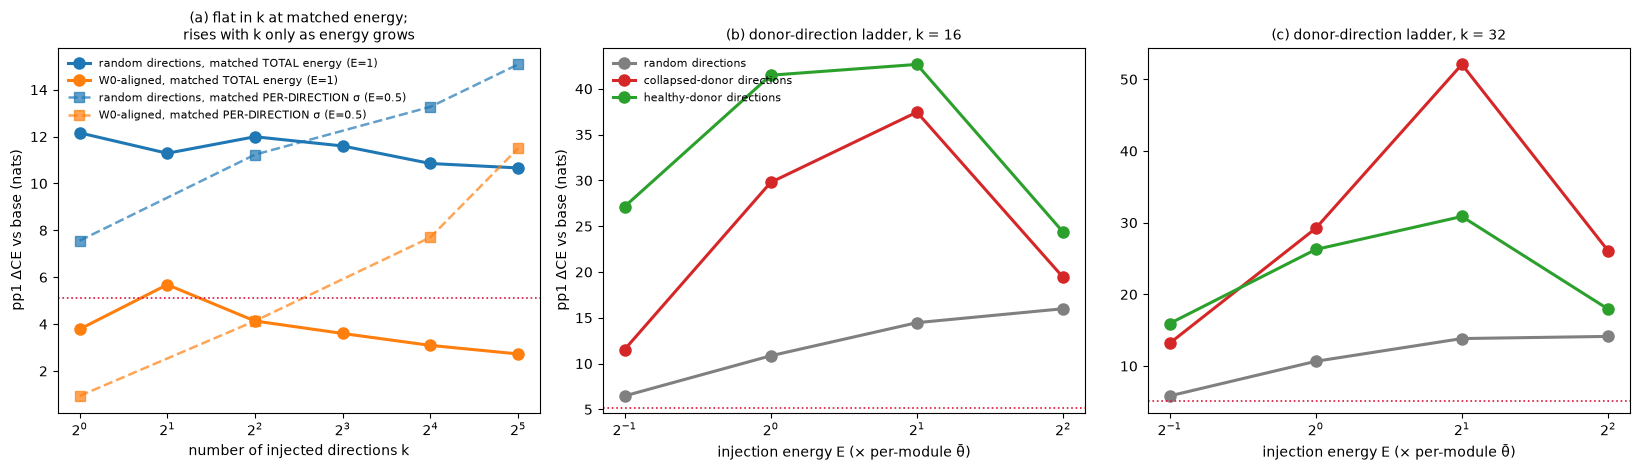

paper anchors: flat-in-k 12.1→10.6 (E=1 generic, k 1→32); trained vs random k=16,E=1: 29.7/41.4 vs 10.8; k=32,E=2: 52.0 vs 13.7


In [7]:
def load_ladder(name):
    fce = A/f'{name}_ce.json'
    d_ = read_json(fce if fce.exists() else A/f'{name}.json')
    fr = pd.DataFrame(d_['results'])
    fr['y'] = fr['delta_ce'] if 'delta_ce' in fr.columns else fr['kl']
    return fr, fce.exists()
dif, lce1 = load_ladder('diffuse_ladder_surgery_ds1')
spc, lce2 = load_ladder('specmatch_ladder_surgery_ds1')
trd, lce3 = load_ladder('trained_direction_ladder_ds1')
YLABL = KL_LAB if (lce1 and lce2 and lce3) else 'pp1 Pile-KL vs base (nats)'
print('ladder sources CE?', dict(diffuse=lce1, specmatch=lce2, trained=lce3))
dif['intr'] = dif.intruder_mods.str.split('/').str[0].astype(int)
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8), sharey=False)
for al, lab, col in (('g', 'random directions', 'tab:blue'), ('a', 'W0-aligned', 'tab:orange')):
    g = dif[(dif['align'] == al) & (dif.E == 1.0)].sort_values('k')
    axes[0].plot(g.k, g.y, 'o-', color=col, lw=2.2, ms=8, label=f'{lab}, matched TOTAL energy (E=1)')
for al, lab, col in (('g', 'random directions', 'tab:blue'), ('a', 'W0-aligned', 'tab:orange')):
    g = spc[(spc['align'] == al) & (spc.E == 0.5)].sort_values('k')
    axes[0].plot(g.k, g.y, 's--', color=col, lw=1.8, ms=7, alpha=0.7, label=f'{lab}, matched PER-DIRECTION σ (E=0.5)')
axes[0].axhline(DC_DS1, color='crimson', ls=':', lw=1.2)
axes[0].set_xscale('log', base=2); axes[0].set_xlabel('number of injected directions k')
axes[0].set_ylabel(YLABL)
axes[0].set_title('(a) flat in k at matched energy;\nrises with k only as energy grows', fontsize=10)
axes[0].legend(fontsize=8, frameon=False)
EE = [0.5, 1.0, 2.0, 4.0]
for ax, k_ in ((axes[1], 16), (axes[2], 32)):
    for lab, cond, col in (('random directions', None, '0.5'),
                           ('collapsed-donor directions', 'tdead', 'tab:red'),
                           ('healthy-donor directions', 'talive', 'tab:green')):
        if cond is None:
            y = [float(dif[(dif['align'] == 'g') & (dif.k == k_) & (dif.E == e)].y.iloc[0]) for e in EE]
        else:
            y = [float(trd[(trd.cond == cond) & (trd.k == k_) & (trd.E == e)].y.iloc[0]) for e in EE]
        ax.plot(EE, y, 'o-', color=col, lw=2.2, ms=8, label=lab)
    ax.axhline(DC_DS1, color='crimson', ls=':', lw=1.2)
    ax.set_xscale('log', base=2); ax.set_xlabel('injection energy E (× per-module θ̄)')
    ax.set_title(f'({"b" if k_ == 16 else "c"}) donor-direction ladder, k = {k_}', fontsize=10)
axes[1].set_ylabel(YLABL)
axes[1].legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig05_injection_ladders.png', dpi=180, bbox_inches='tight'); plt.show()
print('paper anchors: flat-in-k 12.1→10.6 (E=1 generic, k 1→32); trained vs random k=16,E=1: 29.7/41.4 vs 10.8; '
      'k=32,E=2: 52.0 vs 13.7')

## Table 2 — §4.2 / §5.2 *Damage vs intruder counts on the full k × E grid*

**How to read it.** The near-constancy along each ROW of Table 2a is the finding: at matched
total energy, damage does not care how many directions carry it — one strong direction
(k = 1) and 32 weak ones (k = 32) do the same damage. Damage moves only down the COLUMNS
(with total energy E). What *does* change along the rows is Table 2b: the intruder count
collapses as the energy spreads (random position), and is **zero at every cell** for
W₀-aligned position — which still kills from E ≥ 2 (bold in 2a). Damage and intruders
dissociate on the full grid. Data: `diffuse_ladder_surgery_ds1.json` (all-48-module intruder
pass); the trained-direction ladder's intruder spot-check used 8 modules (different
denominator) and is quoted in §5.2 instead.

In [8]:
difl = dif.copy()
difl['position'] = difl['align'].map({'g': 'random directions', 'a': 'W0-aligned'})
kcols = pd.MultiIndex.from_product([['random directions', 'W0-aligned'], [1, 2, 4, 8, 16, 32]],
                                   names=['position', 'k'])
dmg = difl.pivot_table(index='E', columns=['position', 'k'], values='y').reindex(columns=kcols)
intr = difl.pivot_table(index='E', columns=['position', 'k'], values='intr').reindex(columns=kcols)
sty_d = (dmg.style.background_gradient(cmap='RdYlGn_r', axis=None, vmin=0.0, vmax=18.0)
         .format('{:.1f}')
         .map(lambda v: 'font-weight: bold' if pd.notna(v) and v > DC_DS1 else '')
         .set_caption('Table 2a — damage: pp1 Pile-KL vs base (nats), E × (position, k). '
                      'Bold = past the unigram bar. Rows ≈ constant: direction count does not gate damage.'))
sty_i = (intr.style.background_gradient(cmap='Purples', axis=None, vmin=0.0, vmax=48.0)
         .format('{:.0f}')
         .set_caption('Table 2b — intruder modules (of 48) at the same cells: high and k-dependent for random '
                      'position, zero everywhere for W0-aligned.'))
display(sty_d)
display(sty_i)
dmg.to_csv(FIGDIR/'table2a_ladder_damage.csv'); intr.to_csv(FIGDIR/'table2b_ladder_intruders.csv')
al2 = difl[(difl.position == 'W0-aligned') & (difl.E >= 2.0)]
print(f'aligned E≥2 cells: intruders max {int(al2.intr.max())}, damage {al2.y.min():.1f}–{al2.y.max():.1f} nats '
      '— kills with zero intruders')

aligned E≥2 cells: intruders max 0, damage 6.7–14.0 nats — kills with zero intruders


## Figure 6 — §4.3 *The λ-crossing test: per-arm median curves, and crossing sizes vs population θ̂*

**Construction.** `lambda_crossing_arms.jsonl` (160M: strip / orig same-model / trait-free,
12 near-boundary runs each), `lambda_crossing_410m.jsonl` (410M: same-model / cross-seed,
12 each), plus the 08-26 extension `lambda_crossing_ext_*.jsonl` when present (queue
`lambda-ext-crossing`: +12/arm at 160M and new ws1/ws2-receiver ladders). The intervention
is the same λ-rescaling as Figure 2; the *question* differs — Figure 2 established the event
is monotone and nearly reversible in size; here each dialed update's crossing size is a
measurement of its arm's tolerance, compared against the independently fitted population θ̂.
**(a, b)** one line per arm: the median λ curve across that arm's ladders (each ladder
interpolated onto a common dose grid), shaded band = bootstrap 95% CI of the median.
The dot marks where the arm's median per-update crossing lands on the cut; the dashed
vertical is the arm's population θ̂, fit from the endpoint fates of independently trained
runs. **These two measurements need not coincide a priori** — one is an eval-time
intervention on single finished updates, the other an observational fit over a
population — and they coincide only if fate is carried by the endpoint update rather than
the training path (Fig 2's near-reversibility; the clamp shows path effects exist) and
content is an arm constant. Dot-on-dashed-line is therefore the substantive finding, not
a consistency check. Dot–line gaps within the pins' own uncertainty (pooled-logistic
estimates that move ~10% with cut vintage and estimator) are indeterminate; the 410M
same-model gap is the real miss. **How the anchor appears here**: the dead bar is ONE absolute CE threshold
(H_uni = 7.8045 nats); in the plotted excess-over-own-base coordinate it translates to a
per-RECEIVER value Δ_cross = H_uni − ce_base (ds1 5.123 / orig 5.096 / ws1 5.055 /
ws2 5.169; 410M 5.466–5.474 — per receiver, not per arm: strip and trait-free share the
ds1 cut). Every label, crossing, and dot is computed against the run's own receiver's
Δ_cross; ONE cut line is drawn per panel (at the arms' median Δ_cross — the
per-receiver values differ by ≤ 0.11 nats, within line width here), and each crossing dot
sits at its own receiver's exact Δ_cross. **(c)** per-update crossing sizes: median (bar),
bootstrap 95% CI (whisker), pinned θ̂ (star). ws1/ws2 θ̂ pins (0.113 / 0.141) and the 410M
pins are population fits of their era; the declared-cut comparison is printed below.

CE-rerun arms: ['cross-seed(410m)', 'samemodel(410m)', 'samemodel(orig)', 'strip(ds1)', 'traitfree(ds1)', 'ws1', 'ws2']
λ-crossing sources loaded: ['lambda_crossing_arms', 'lambda_crossing_410m', 'lambda_crossing_ext_samemodel', 'lambda_crossing_ext_strip', 'lambda_crossing_ext_traitfree', 'lambda_crossing_ext_ws1', 'lambda_crossing_ext_ws2', 'lambda_crossing_ce_m410cross', 'lambda_crossing_ce_m410same', 'lambda_crossing_ce_samemodel', 'lambda_crossing_ce_strip', 'lambda_crossing_ce_traitfree', 'lambda_crossing_ce_ws1', 'lambda_crossing_ce_ws2']
ladders per arm: {'cross-seed(410m)': 12, 'samemodel(410m)': 12, 'samemodel(orig)': 24, 'strip(ds1)': 24, 'traitfree(ds1)': 24, 'ws1': 12, 'ws2': 12}


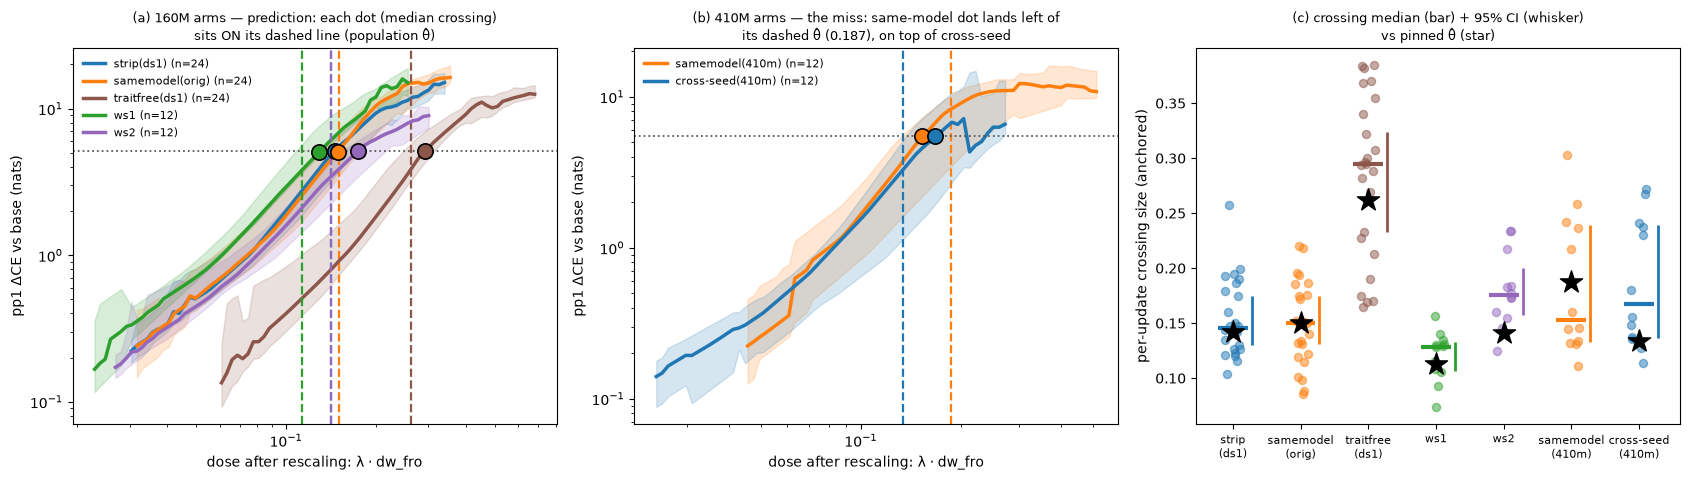

anchored crossing medians: {'cross-seed(410m)': 0.168, 'samemodel(410m)': 0.153, 'samemodel(orig)': 0.15, 'strip(ds1)': 0.146, 'traitfree(ds1)': 0.294, 'ws1': 0.129, 'ws2': 0.175}
θ̂ pins: {'strip(ds1)': 0.142, 'samemodel(orig)': 0.15, 'traitfree(ds1)': 0.262, 'ws1': 0.113, 'ws2': 0.141, 'samemodel(410m)': 0.187, 'cross-seed(410m)': 0.134}
trait-free/strip ratio: 2.02 (predicted ~1.9)
declared 4.0 comparison medians: {'cross-seed(410m)': 0.146, 'samemodel(410m)': 0.137, 'samemodel(orig)': 0.136, 'strip(ds1)': 0.131, 'traitfree(ds1)': 0.267, 'ws1': 0.115, 'ws2': 0.153}


In [9]:
_dose_cache = {}
def dose_of(run):
    if run not in _dose_cache: _dose_cache[run] = pooled_dose(run)
    return _dose_cache[run]
files = [A/'lambda_crossing_arms.jsonl', A/'lambda_crossing_410m.jsonl'] + sorted(A.glob('lambda_crossing_ext_*.jsonl'))
cefiles = sorted(A.glob('lambda_crossing_ce_*.jsonl'))
frames = []
for f in files + cefiles:
    if f.exists() and f.stat().st_size > 0:
        d_ = read_jsonl(f); d_['src'] = f.stem
        d_['is_ce'] = 'delta_ce' in d_.columns
        d_['y'] = d_['delta_ce'] if 'delta_ce' in d_.columns else d_['pile_kl']
        frames.append(d_)
lam = pd.concat(frames, ignore_index=True)
def arm_of(r):
    if '/students/controls/' in r: return 'traitfree(ds1)'
    m = re.search(r'/students/dog/(pythia-[^/]+)/', r)
    return {'pythia-160m': 'samemodel(orig)', 'pythia-160m-data-seed1': 'strip(ds1)',
            'pythia-160m-weight-seed1': 'ws1', 'pythia-160m-weight-seed2': 'ws2',
            'pythia-410m': 'samemodel(410m)', 'pythia-410m-seed1': 'cross-seed(410m)'}[m.group(1)]
lam['arm'] = lam.run.map(arm_of)
BKEY = {'traitfree(ds1)': 'pythia-160m-data-seed1', 'strip(ds1)': 'pythia-160m-data-seed1',
        'samemodel(orig)': 'pythia-160m', 'ws1': 'pythia-160m-weight-seed1',
        'ws2': 'pythia-160m-weight-seed2', 'samemodel(410m)': 'pythia-410m',
        'cross-seed(410m)': 'pythia-410m-seed1'}
lam['cut'] = lam.arm.map(BKEY).map(DCX)
ce_arms = set(lam[lam.is_ce].arm.unique())
lam = pd.concat([lam[lam.arm.isin(ce_arms) & lam.is_ce], lam[~lam.arm.isin(ce_arms)]], ignore_index=True)
present = set(lam.arm.unique())
YLAB6 = KL_LAB if ce_arms >= present else ('pp1 ΔCE (CE-rerun arms) / Pile-KL (legacy arms) vs base (nats)' if ce_arms else 'pp1 Pile-KL vs base (nats)')
print('CE-rerun arms:', sorted(ce_arms) or 'none yet (ce-wave1 pending)')
print('λ-crossing sources loaded:', [fr.src.iloc[0] for fr in frames])
ext_present = sorted(a for a in ('ws1', 'ws2') if a in present)
print('ladders per arm:', lam.groupby('arm').run.nunique().to_dict())
if not ext_present:
    print('extension arms (ws1/ws2): none yet — queue lambda-ext-crossing pending; re-execute after it drains')
THETA = {'strip(ds1)': 0.142, 'samemodel(orig)': 0.150, 'traitfree(ds1)': 0.262,
         'ws1': 0.113, 'ws2': 0.141, 'samemodel(410m)': 0.187, 'cross-seed(410m)': 0.134}
LCOL = {'strip(ds1)': 'tab:blue', 'samemodel(orig)': 'tab:orange', 'traitfree(ds1)': 'tab:brown',
        'ws1': 'tab:green', 'ws2': 'tab:purple',
        'samemodel(410m)': 'tab:orange', 'cross-seed(410m)': 'tab:blue'}

def band_panel(ax, arms):
    for a in arms:
        g = lam[lam.arm == a]
        curves_ = []
        for run, gg in g.groupby('run'):
            gg = gg.sort_values('lam')
            x = np.log(gg.lam.values * dose_of(run)); y = np.log(np.maximum(gg.y.values, 1e-3))
            curves_.append((x, y))
        gridlo = float(np.median([c[0].min() for c in curves_])); gridhi = float(np.median([c[0].max() for c in curves_]))
        grid = np.linspace(gridlo, gridhi, 60)
        M = np.full((len(curves_), 60), np.nan)
        for i, (x, y) in enumerate(curves_):
            msk = (grid >= x.min()) & (grid <= x.max())
            M[i, msk] = np.interp(grid[msk], x, y)
        rb = np.random.default_rng(4)
        boots = np.full((400, 60), np.nan)
        for b_ in range(400):
            boots[b_] = np.nanmedian(M[rb.integers(0, len(curves_), len(curves_))], axis=0)
        med = np.exp(np.nanmedian(M, axis=0))
        loB = np.exp(np.nanpercentile(boots, 2.5, axis=0)); hiB = np.exp(np.nanpercentile(boots, 97.5, axis=0))
        cov = (~np.isnan(M)).sum(axis=0) >= max(4, len(curves_) // 2)
        gx = np.exp(grid)
        ax.plot(gx[cov], med[cov], '-', color=LCOL[a], lw=2.5, label=f'{a} (n={len(curves_)})')
        ax.fill_between(gx[cov], loB[cov], hiB[cov], color=LCOL[a], alpha=0.18)
        ax.axvline(THETA[a], color=LCOL[a], ls='--', lw=1.6)
        cut_a = lam[lam.arm == a].cut.iloc[0]
        dm = cc[cc.arm == a].cross.median()
        ax.plot([dm], [cut_a], 'o', color=LCOL[a], ms=11, mec='k', mew=1.2, zorder=5)
    ax.axhline(float(np.median([lam[lam.arm == a].cut.iloc[0] for a in arms])), color='0.35', ls=':', lw=1.3)
    ax.set_xscale('log'); ax.set_yscale('log')
    from matplotlib.ticker import NullFormatter
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel('dose after rescaling: λ · dw_fro'); ax.set_ylabel(YLAB6)
    ax.legend(fontsize=8, frameon=False, loc='upper left')

def crossings(df_, declared=False):
    rows_ = []
    for run, g in df_.groupby('run'):
        g = g.sort_values('lam')
        cut = DEAD_KL_CUT if declared else g.cut.iloc[0]
        lstar = interp_crossing(list(g.lam.values), list(g.y.values), cut, rising=True)
        if np.isfinite(lstar): rows_.append(dict(arm=g.arm.iloc[0], cross=lstar * dose_of(run)))
    return pd.DataFrame(rows_)
cc = crossings(lam)
arms160 = [a for a in ('strip(ds1)', 'samemodel(orig)', 'traitfree(ds1)', 'ws1', 'ws2') if a in present]
arms410 = [a for a in ('samemodel(410m)', 'cross-seed(410m)') if a in present]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
band_panel(axes[0], arms160)
axes[0].set_title('(a) 160M arms — prediction: each dot (median crossing)\nsits ON its dashed line (population θ̂)', fontsize=9)
band_panel(axes[1], arms410)
axes[1].set_title('(b) 410M arms — the miss: same-model dot lands left of\nits dashed θ̂ (0.187), on top of cross-seed', fontsize=9)
def crossings(df_, declared=False):
    rows_ = []
    for run, g in df_.groupby('run'):
        g = g.sort_values('lam')
        cut = DEAD_KL_CUT if declared else g.cut.iloc[0]
        lstar = interp_crossing(list(g.lam.values), list(g.pile_kl.values), cut, rising=True)
        if np.isfinite(lstar): rows_.append(dict(arm=g.arm.iloc[0], cross=lstar * dose_of(run)))
    return pd.DataFrame(rows_)
cc = crossings(lam)
order = arms160 + arms410
rj = np.random.default_rng(0)
for j, a in enumerate(order):
    v = cc[cc.arm == a].cross.values
    axes[2].scatter(j + rj.uniform(-0.12, 0.12, len(v)), v, s=34, alpha=0.5, color=LCOL[a])
    m, lo, hi = med_ci(v)
    axes[2].hlines(m, j-0.22, j+0.22, color=LCOL[a], lw=3)
    axes[2].vlines(j+0.28, lo, hi, color=LCOL[a], lw=2)
    axes[2].scatter([j], [THETA[a]], marker='*', s=280, color='k', zorder=4)
axes[2].set_xticks(range(len(order)))
axes[2].set_xticklabels([a.replace('(', '\n(') for a in order], fontsize=8)
axes[2].set_ylabel('per-update crossing size (anchored)')
axes[2].set_title('(c) crossing median (bar) + 95% CI (whisker)\nvs pinned θ̂ (star)', fontsize=9)
plt.tight_layout(); fig.savefig(FIGDIR/'fig06_lambda_crossing.png', dpi=180, bbox_inches='tight'); plt.show()
print('anchored crossing medians:', cc.groupby('arm').cross.median().round(3).to_dict())
print('θ̂ pins:', THETA)
if 'traitfree(ds1)' in present and 'strip(ds1)' in present:
    print('trait-free/strip ratio:',
          round(cc[cc.arm=="traitfree(ds1)"].cross.median()/cc[cc.arm=="strip(ds1)"].cross.median(), 2),
          '(predicted ~1.9)')
print('declared 4.0 comparison medians:', crossings(lam, declared=True).groupby('arm').cross.median().round(3).to_dict())

## Figure 7 — §4.3 / §4.4 *The dose map, and size → fate (strip arm)*

**Construction.** Strip arm throughout (orig-teacher numbers → ds1 receiver, ep20). **(a)**
observed dw_fro vs the single global power-law fit lr^a·α^b·r^c, points colored by α. The
map is *deliberately shown against a straight power law*: the systematic, α-ordered bowing
around the diagonal IS the curvature of §4.4 (the boundary's b-bend inherits it); the global
exponents are the support-weighted average. **(b)** size → fate with the actual data: each
circle is one (lr, α, r) grid cell (its runs' death fraction vs its median size, area ∝
number of runs); the gray rug is every individual run at 0/1 (jittered); the red line is the
run-level logistic fit.

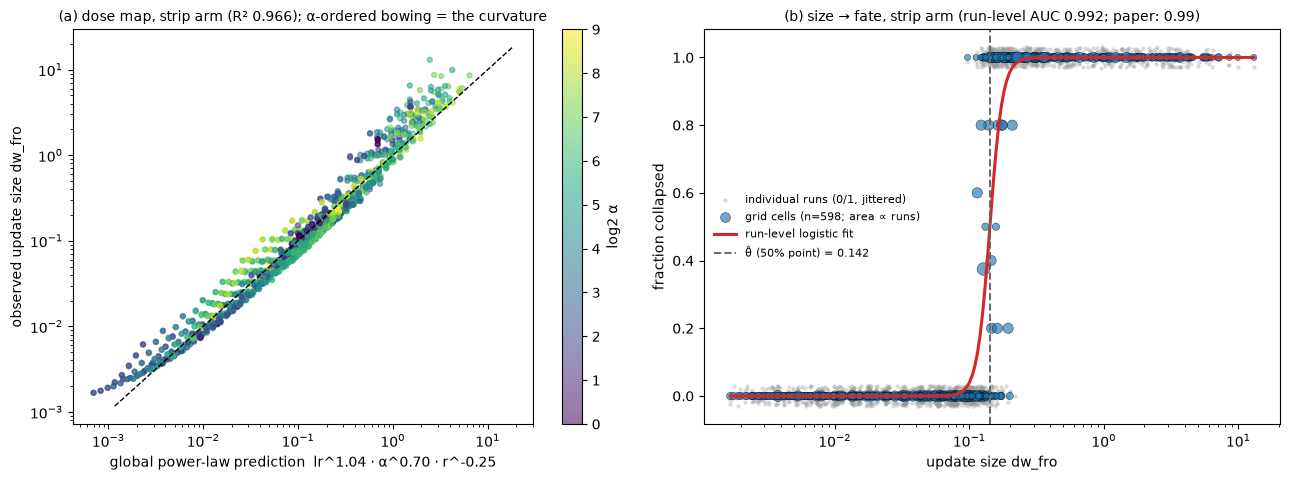

dose map exponents: lr 1.04, α 0.70, r -0.25 (R² 0.966) | run-level dose→fate AUC 0.992


In [10]:
X = sm.add_constant(pd.DataFrame({'llr': np.log(sd.lr), 'la': np.log(sd.alpha), 'lrk': np.log(sd['rank'])}))
fmap = sm.OLS(np.log(sd.dw), X).fit(cov_type='cluster', cov_kwds={'groups': sd.tag})
sd['dw_pred'] = np.exp(fmap.fittedvalues)
auc = roc_auc_score(sd.dead, sd.dw)
lg = sm.Logit(sd.dead.astype(int), sm.add_constant(np.log(sd.dw))).fit(disp=0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.9))
sc = axes[0].scatter(sd.dw_pred, sd.dw, s=13, alpha=0.55, c=np.log2(sd.alpha), cmap='viridis')
cb = fig.colorbar(sc, ax=axes[0]); cb.set_label('log2 α')
lim = [sd.dw.min()*0.7, sd.dw.max()*1.4]
axes[0].plot(lim, lim, 'k--', lw=1)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel(f'global power-law prediction  lr^{fmap.params.llr:.2f} · α^{fmap.params.la:.2f} · r^{fmap.params.lrk:.2f}')
axes[0].set_ylabel('observed update size dw_fro')
axes[0].set_title(f'(a) dose map, strip arm (R² {fmap.rsquared:.3f}); α-ordered bowing = the curvature', fontsize=10)
cells = sd.groupby('tag').agg(dw=('dw', 'median'), frac=('dead', 'mean'), n=('dead', 'size')).reset_index()
xs = np.geomspace(sd.dw.min(), sd.dw.max(), 200)
rj = np.random.default_rng(2)
axes[1].scatter(sd.dw, sd.dead.astype(float) + rj.uniform(-0.03, 0.03, len(sd)), s=5, color='0.6', alpha=0.25,
                label='individual runs (0/1, jittered)')
axes[1].scatter(cells.dw, cells.frac, s=10 + 9*cells.n, color='tab:blue', alpha=0.65,
                edgecolor='k', lw=0.4, label=f'grid cells (n={len(cells)}; area ∝ runs)')
axes[1].plot(xs, lg.predict(sm.add_constant(np.log(xs))), '-', color='tab:red', lw=2.2, label='run-level logistic fit')
theta50 = np.exp(-lg.params.iloc[0]/lg.params.iloc[1])
axes[1].axvline(theta50, color='0.4', ls='--', lw=1.4, label=f'θ̂ (50% point) = {theta50:.3f}')
axes[1].set_xscale('log'); axes[1].set_xlabel('update size dw_fro'); axes[1].set_ylabel('fraction collapsed')
axes[1].set_title(f'(b) size → fate, strip arm (run-level AUC {auc:.3f}; paper: 0.99)', fontsize=10)
axes[1].legend(fontsize=8, frameon=False, loc='center left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig07_dose_map_fate.png', dpi=180, bbox_inches='tight'); plt.show()
print(f'dose map exponents: lr {fmap.params.llr:.2f}, α {fmap.params.la:.2f}, r {fmap.params.lrk:.2f} '
      f'(R² {fmap.rsquared:.3f}) | run-level dose→fate AUC {auc:.3f}')

## Figure 8 — §4.4 *[earlier program] Frozen vs learned: share of the full update norm, and the strip component splices*

**Construction.** The update factorizes exactly as ΔW = s·B·A₀ + s·B·ΔA — a *frozen*
component (trained B against the frozen random init A₀) and a *learned* component (trained B
against the trained change ΔA). **(a)** the learned component's share of the **actual full
update norm**, ‖B·ΔA‖_F/‖B·A_final‖_F (pooled over modules; can exceed 1 when the components
cancel), box plots by α over the strip's full-schema runs — learned-dominated at low α,
frozen-dominated at high α: the balance whose motion along α the boundary's b-bend inherits.
**(b)** the strip component splice (`frozen_a_ablation_strip_*`, 8 ranks × 2 seeds over the
whole strip): **trait retention** (excess p(dog) over base prior retained after keeping only
one component; trait-carrying runs, the nors_asks §5.4 readout), box plots by α — the
carrier migrates from the learned to the frozen component as α grows. **(c)** the same
splices read on **pp1 Pile-KL**: full update vs keep-frozen vs keep-learned, box plots by α.
Provenance: earlier-program experiments (A2); the v2 ledger carries only the curvature
statement.

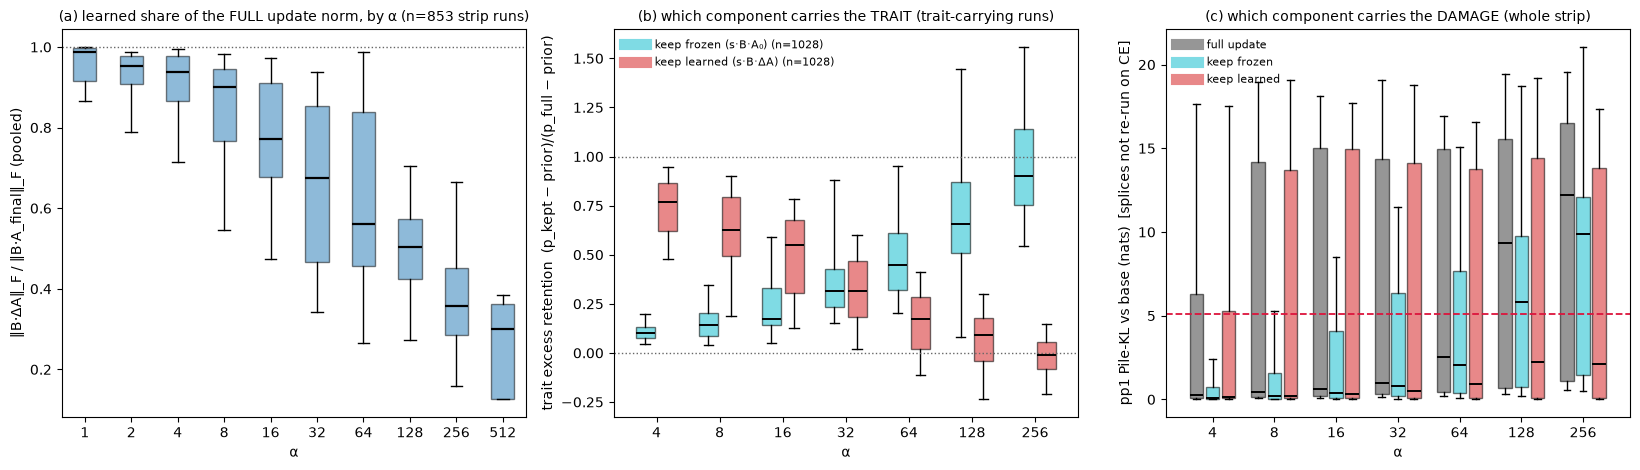

learned share (of full norm) medians by α: {1: 0.99, 2: 0.95, 4: 0.94, 8: 0.9, 16: 0.77, 32: 0.67, 64: 0.56, 128: 0.5, 256: 0.36, 512: 0.3}
trait-carrying splice rows: keep-frozen 1028, keep-learned 1028 (of 1864/1864)


In [11]:
hs = sd.dropna(subset=['dw_frozen', 'dw_learned']).copy()
hs['learned_share'] = hs.dw_learned / hs.dw
def load_strip_splice(which):
    frames_, pb = [], None
    for f in sorted(A.glob(f'frozen_a_ablation_strip_{which}_r*_s*.json')):
        d_ = read_json(f); pb = d_['p_target_base']
        frames_.append(pd.DataFrame(d_['results']))
    return (pd.concat(frames_) if frames_ else pd.DataFrame()), pb
sfz, pb_s = load_strip_splice('frozen')
smv, _ = load_strip_splice('moved')
for fr in (sfz, smv):
    fr['excess_retention'] = (fr.p_target_ablated - pb_s) / (fr.p_target_orig - pb_s)
tcf = sfz[sfz.p_target_orig > 0.02]; tcm = smv[smv.p_target_orig > 0.02]
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.8))
al = sorted(hs.alpha.unique()); pos = np.arange(len(al), dtype=float)
bp = axes[0].boxplot([hs.loc[hs.alpha == a_, 'learned_share'].values for a_ in al],
                     positions=pos, widths=0.5, whis=(5, 95), showfliers=False,
                     patch_artist=True, medianprops=dict(color='black', lw=1.6))
for b_ in bp['boxes']: b_.set(facecolor='tab:blue', alpha=0.5)
axes[0].axhline(1.0, color='0.4', ls=':', lw=1)
axes[0].set_xticks(pos); axes[0].set_xticklabels(al)
axes[0].set_xlabel('α'); axes[0].set_ylabel('‖B·ΔA‖_F / ‖B·A_final‖_F (pooled)')
axes[0].set_title(f'(a) learned share of the FULL update norm, by α (n={len(hs)} strip runs)', fontsize=10)
al2 = sorted(set(tcf.alpha) | set(tcm.alpha)); pos2 = np.arange(len(al2), dtype=float)
for lab, frame, color, off in (('keep frozen (s·B·A₀)', tcf, 'tab:cyan', -0.18),
                               ('keep learned (s·B·ΔA)', tcm, 'tab:red', 0.18)):
    data = [frame.loc[frame.alpha == a_, 'excess_retention'].dropna().values for a_ in al2]
    bp = axes[1].boxplot(data, positions=pos2 + off, widths=0.3, whis=(5, 95), showfliers=False,
                         patch_artist=True, medianprops=dict(color='black', lw=1.4))
    for b_ in bp['boxes']: b_.set(facecolor=color, alpha=0.55)
    axes[1].plot([], [], color=color, lw=8, alpha=0.55, label=f'{lab} (n={sum(len(d_) for d_ in data)})')
axes[1].axhline(1.0, color='0.4', ls=':', lw=1); axes[1].axhline(0.0, color='0.4', ls=':', lw=1)
axes[1].set_xticks(pos2); axes[1].set_xticklabels(al2)
axes[1].set_xlabel('α'); axes[1].set_ylabel('trait excess retention  (p_kept − prior)/(p_full − prior)')
axes[1].set_title('(b) which component carries the TRAIT (trait-carrying runs)', fontsize=10)
axes[1].legend(fontsize=8, frameon=False)
for lab, ser_by_a, color, off in (('full update', sfz.groupby('alpha').pile_kl_base_orig, '0.25', -0.26),
                                  ('keep frozen', sfz.groupby('alpha').pile_kl_base_ablated, 'tab:cyan', 0.0),
                                  ('keep learned', smv.groupby('alpha').pile_kl_base_ablated, 'tab:red', 0.26)):
    data = [ser_by_a.get_group(a_).dropna().values if a_ in ser_by_a.groups else np.array([]) for a_ in al2]
    bp = axes[2].boxplot([d_ for d_ in data], positions=pos2 + off, widths=0.22, whis=(5, 95), showfliers=False,
                         patch_artist=True, medianprops=dict(color='black', lw=1.4))
    for b_ in bp['boxes']: b_.set(facecolor=color, alpha=0.55)
    axes[2].plot([], [], color=color, lw=8, alpha=0.55, label=lab)
axes[2].axhline(DC_DS1, color='crimson', ls='--', lw=1.3)
axes[2].set_xticks(pos2); axes[2].set_xticklabels(al2)
axes[2].set_xlabel('α'); axes[2].set_ylabel('pp1 Pile-KL vs base (nats)  [splices not re-run on CE]')
axes[2].set_title('(c) which component carries the DAMAGE (whole strip)', fontsize=10)
axes[2].legend(fontsize=8, frameon=False, loc='upper left')
plt.tight_layout(); fig.savefig(FIGDIR/'fig08_frozen_learned.png', dpi=180, bbox_inches='tight'); plt.show()
print('learned share (of full norm) medians by α:', hs.groupby('alpha').learned_share.median().round(2).to_dict())
print(f'trait-carrying splice rows: keep-frozen {len(tcf)}, keep-learned {len(tcm)} (of {len(sfz)}/{len(smv)})')

## Figure 9 — §4.7 *The two-curve figure (cut-free presentation)*

**Construction.** Orig same-model arm (tier-B run list, fixed teacher cell
`ep2_lr5e-4_r32a64`). x: the K placement coordinate over its calibrated anchor
(K = lr·α^0.561·r^−0.085 / 8.4e-4 — a display coordinate for run placement, not a fitted
claim of this paper). Geometric K bins (n ≥ 5); per bin the median trait ratio p(dog)/prior
on the held-out test set (green, left axis) and the median pp1 Pile-KL (red, right axis),
2,000-resample bootstrap 95% CIs. Vertical landmark: where binned median ΔCE crosses the
anchored unigram bar Δ_cross(orig). No binary label anywhere.

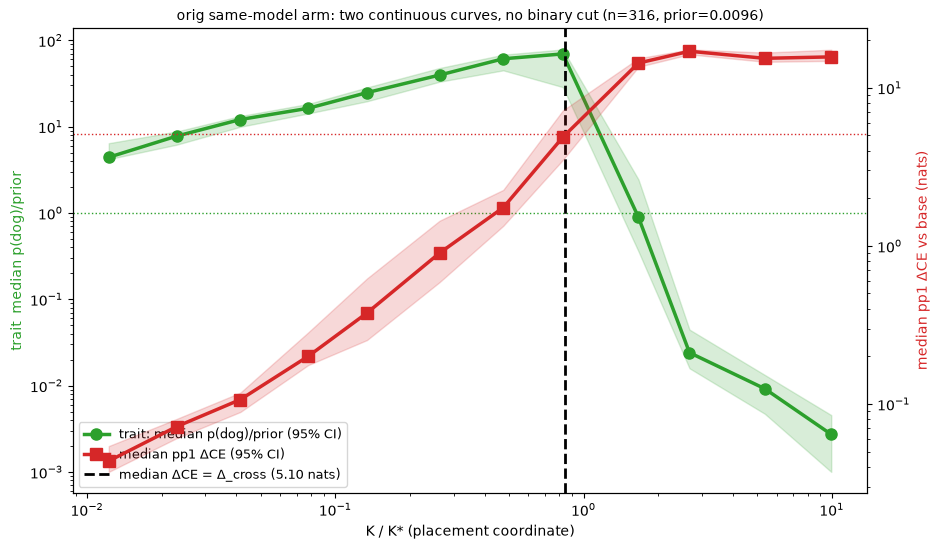

In [12]:
be = read_json(A/'base_eval_original_animal_preference_test.json')
prior = float(np.mean(be['dog']['p_per_prompt']))
B_, C_, KCAL = 0.561, -0.085, 8.4e-4
rows = []
for line in Path(REPO/'run_logs/harvest_20260824/tierb_orig_runs.txt').read_text().splitlines():
    rd = Path(line.strip())
    if not line.strip() or 'ep2_lr5e-4_r32a64' not in str(rd): continue
    try:
        pp_ = json.loads((rd/'eval'/'pile_probe.json').read_text())
        pe = json.loads((rd/'preference_eval.json').read_text())
    except FileNotFoundError: continue
    pt = parse_param_tag(rd.parent.name)
    rows.append(dict(K=pt['lr']*pt['alpha']**B_*pt['rank']**C_/KCAL, kl=pp_.get('delta_ce'),
                     dce=pp_.get('delta_ce'), p=pe.get('sets', {}).get('test', {}).get('p_target')))
tc2 = pd.DataFrame(rows).dropna(); tc2 = tc2[np.isfinite(tc2.kl)]; tc2['ratio'] = tc2.p/prior
gbins = np.geomspace(tc2.K.min()*0.99, tc2.K.max()*1.01, 14)
tc2['bin'] = pd.cut(tc2.K, gbins)
recs = []
for b_, g_ in tc2.groupby('bin', observed=True):
    if len(g_) < 5: continue
    r_m, r_lo, r_hi = med_ci(g_.ratio.values); k_m, k_lo, k_hi = med_ci(g_.kl.values)
    recs.append(dict(K=g_.K.median(), r=r_m, rlo=r_lo, rhi=r_hi, kl=k_m, kllo=k_lo, klhi=k_hi, dce=g_.dce.median(), n=len(g_)))
gg = pd.DataFrame(recs).sort_values('K')
crossK = np.interp(DC_ORIG, gg.dce.values, gg.K.values)
fig, ax1 = plt.subplots(figsize=(9.5, 5.6)); ax2 = ax1.twinx()
ax1.fill_between(gg.K, np.maximum(gg.rlo, 1e-3), gg.rhi, color='tab:green', alpha=0.18)
l1, = ax1.plot(gg.K, gg.r, 'o-', color='tab:green', lw=2.5, ms=8, label='trait: median p(dog)/prior (95% CI)')
ax1.axhline(1.0, color='tab:green', ls=':', lw=1)
ax2.fill_between(gg.K, np.maximum(gg.kllo, 1e-3), gg.klhi, color='tab:red', alpha=0.18)
l2, = ax2.plot(gg.K, gg.kl, 's-', color='tab:red', lw=2.5, ms=8, label='median pp1 ΔCE (95% CI)')
ax2.axhline(DC_ORIG, color='tab:red', ls=':', lw=1)
vl = ax1.axvline(crossK, color='black', ls='--', lw=2)
ax1.set_xscale('log'); ax1.set_yscale('log'); ax2.set_yscale('log')
ax1.set_xlabel('K / K* (placement coordinate)'); ax1.set_ylabel('trait  median p(dog)/prior', color='tab:green')
ax2.set_ylabel('median pp1 ΔCE vs base (nats)', color='tab:red')
ax1.set_title(f'orig same-model arm: two continuous curves, no binary cut (n={len(tc2)}, prior={prior:.4f})', fontsize=10)
ax1.legend(handles=[l1, l2, vl], labels=[l1.get_label(), l2.get_label(), f'median ΔCE = Δ_cross ({DC_ORIG:.2f} nats)'],
           loc='lower left', frameon=True, fontsize=9)
plt.tight_layout(); fig.savefig(FIGDIR/'fig09_two_curves.png', dpi=180, bbox_inches='tight'); plt.show()

## Figure 10 — §4.7 *Trait and damage ride the same directions*

**What this figure says.** The direction randomization that heals the model (Table 1) also
deletes the subliminal trait: in every surgery run — healthy or collapsed, student or
teacher — p(dog) at random position falls to at or below the untuned base's prior. Carrier
and damage are properties of the same direction content, which is the mechanism behind
§4.7's claim that the boundary is not subliminal learning's edge. One panel per teacher-data
arm; each line is one run, trained → random position, log scale, base prior dotted.

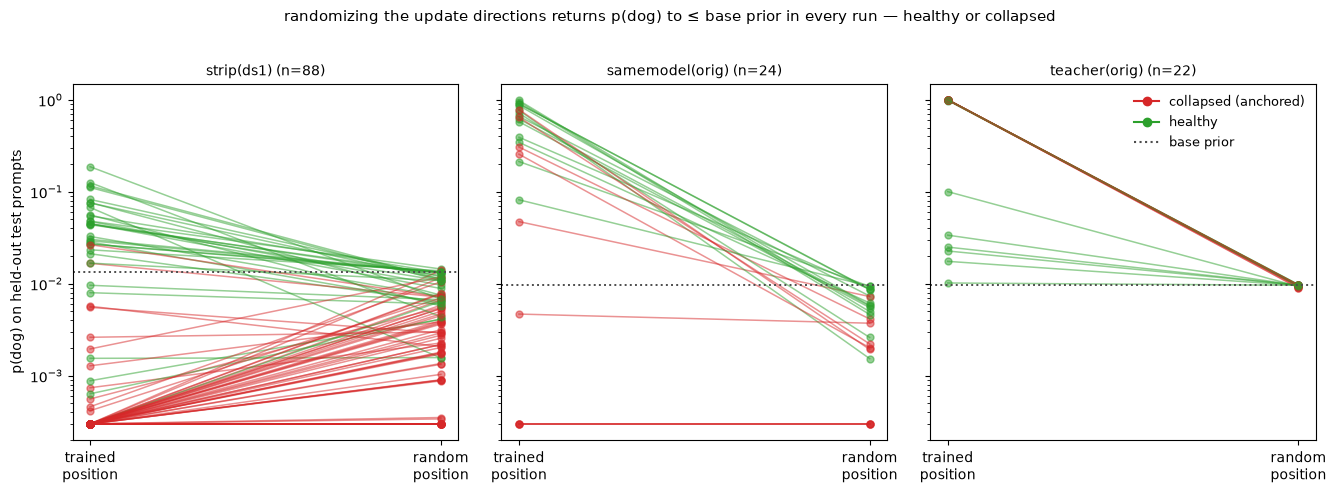

p(dog) medians trained → random, by arm × anchored fate (ledger campaign medians are label-composition-sensitive on the trained side; the deletion endpoints match):
                       p_orig  p_rand
arm             dead                 
samemodel(orig) False  0.6880  0.0060
                True   0.0260  0.0020
strip(ds1)      False  0.0438  0.0097
                True   0.0000  0.0023
teacher(orig)   False  0.5414  0.0096
                True   1.0000  0.0095


In [13]:
PRIOR_ORIG, PRIOR_DS1 = 0.0096, 0.0133
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), sharey=True)
lo = 3e-4
for ax, a in zip(axes, ['strip(ds1)', 'samemodel(orig)', 'teacher(orig)']):
    g = mm[mm.arm == a]
    for _, r in g.iterrows():
        col = 'tab:red' if r.dead else 'tab:green'
        ax.plot([0, 1], [max(r.orig_p, lo), max(r.randm_p, lo)], '-o', color=col, alpha=0.5, lw=1.1, ms=5)
    ax.axhline(PRIOR_ORIG if 'orig' in a else PRIOR_DS1, color='0.3', ls=':', lw=1.4)
    ax.set_yscale('log'); ax.set_xticks([0, 1]); ax.set_xticklabels(['trained\nposition', 'random\nposition'])
    ax.set_title(f'{a} (n={len(g)})', fontsize=10)
axes[0].set_ylabel('p(dog) on held-out test prompts')
h = [plt.Line2D([], [], color='tab:red', marker='o', label='collapsed (anchored)'),
     plt.Line2D([], [], color='tab:green', marker='o', label='healthy'),
     plt.Line2D([], [], color='0.3', ls=':', label='base prior')]
axes[2].legend(handles=h, fontsize=9, frameon=False, loc='upper right')
fig.suptitle('randomizing the update directions returns p(dog) to ≤ base prior in every run — healthy or collapsed',
             fontsize=11, y=1.02)
plt.tight_layout(); fig.savefig(FIGDIR/'fig10_trait_deletion.png', dpi=180, bbox_inches='tight'); plt.show()
print('p(dog) medians trained → random, by arm × anchored fate (ledger campaign medians are '
      'label-composition-sensitive on the trained side; the deletion endpoints match):')
print(mm[mm.arm.isin(['strip(ds1)', 'samemodel(orig)', 'teacher(orig)'])]
      .groupby(['arm', 'dead']).agg(p_orig=('orig_p', 'median'), p_rand=('randm_p', 'median')).round(4).to_string())

---
**Provenance.** Artifacts: `position_surgery_v2*.jsonl`, `lambda_crossing_{arms,410m}.jsonl`
(+ `lambda_crossing_ext_*.jsonl`, queue `lambda-ext-crossing`, run lists in
`run_logs/lambda_ext_20260826/`),
`frozen_a_ablation_{scale,revival,lamstrat*,shellext*,ws1lam}_lam*_pp1.json` (λ families),
`frozen_a_ablation_strip_{frozen,moved}_r*_s*.json` (component splices),
`{diffuse,specmatch}_ladder_surgery_ds1.json`, `trained_direction_ladder_ds1.json`,
`unigram_anchor_pp1.json` (via `probe_io.anchored_dead_cut`),
`base_eval_original_animal_preference_test.json`, the `clamp_students/` tree, and
strip/tier-B run-dir records. Producers are committed under `scripts/`; analysis homes:
`collapse_surgery_and_sgd.ipynb` (08-24→26 program), `collapse_claims.ipynb` (λ/clamp/
hysteresis era), `nors_asks.ipynb` (component splices). Fig 8 renders earlier-program (A2)
experiments by request, provenance-tagged; the spread splice was dropped 08-26 as
inconclusive (artifacts remain in `spread_ladder_*.json`). Paper:
`docs/results/collapse_two_factor_iclr.md`; claim ledger: `collapse_claims_v2.md`.